A Simple Guide to Image Regression Using FastAI

This tutorial demonstrates how to train a basic image-regression model using FastAI.

The example dataset contains procedurally generated RGB images of several geometric shapes. The workflow is intentionally simple so that the example images and numerical target variable can be replaced with data from another application.


The first step is to import the Python packages required for the tutorial.

Pandas is used to organise and work with tabular data, while FastAI provides the tools required to construct and train the image-regression model.


In [1]:
import pandas as pd
from fastai.vision.all import * # .vision.all imports image based fastai 

The following block checks whether the example dataset is already available.

If the required data cannot be found, the notebook runs Generating_basic_data.ipynb to create the example dataset.

If you are using your own dataset, this step can be omitted or modified as required.


In [2]:
Dataframe_path = '../image_data_assorted.csv'

if os.path.exists(Dataframe_path):
    print("The file exists.")
else:
    %run ../Generating_basic_data.ipynb

The file exists.


The next step is to load the dataframe containing the image paths and associated numerical data. For this regression task, the target variable is the Radius column, which the model will be trained to predict from each image.


In [3]:

df = pd.read_csv('../image_data_assorted.csv')

The supplied example dataset contains 1,000 procedurally generated images of geometric shapes.

The two columns required for this tutorial are:

1. image_path: contains the file path used to locate and load each image.

2. Radius: contains the numerical target value that the model will be trained to predict.

The dataframe also contains several additional generated variables that can be used as alternative regression targets.


In [4]:
df.head()

,Radius,X_Position,Y_Position,Area,Surface2d,Volume,image_path,mask_path,shape
0,57,82,279,3249,228,185193,../images_assorted/image_1.png,../masks_assorted/mask_1.png,square
1,94,347,290,8836,376,830584,../images_assorted/image_2.png,../masks_assorted/mask_2.png,square
2,42,79,332,1764,168,74088,../images_assorted/image_3.png,../masks_assorted/mask_3.png,square
3,88,248,182,24316,276,2853096,../images_assorted/image_4.png,../masks_assorted/mask_4.png,circle
4,74,430,381,17195,232,1696538,../images_assorted/image_5.png,../masks_assorted/mask_5.png,circle


We next define two functions that specify how FastAI should extract the model inputs and targets from the dataframe. For image regression, the model requires an image as its input and a numerical value as its target.

During training, each function receives one row of the dataframe as a Pandas Series. The get_inputs function reads the file path stored in the image_path column and loads the corresponding image as a PILImage.

The get_target function extracts the numerical value stored in the Radius column.


In [5]:
def get_inputs(row):
    # Open and returns image using the image path 
    image_data = PILImage.create(row['image_path'])
    return image_data 

def get_target(row):
    # returns to a numerical value stored in 'Radius' column
    target_data = row['Radius']
    return target_data

A FastAI DataBlock defines how the training data are organised and supplied to the model. In this tutorial, only the settings required for a basic image-regression task are used.

The blocks argument specifies the types of input and target data. Because the input is an image and the target is a continuous numerical value, the appropriate configuration is:

blocks=(ImageBlock, RegressionBlock)

ImageBlock specifies that the model input is image data, while RegressionBlock specifies that the target is numerical.

The previously defined getter functions are then assigned using:

get_x=get_inputs
get_y=get_target

Here, get_x specifies how the input data are obtained and get_y specifies how the target data are obtained.

Two additional options are included as commented examples.

RandomSplitter can be used to control how the dataset is divided into training and validation subsets. The role of validation data is discussed in greater detail in the Chapter 2 appendix.

Resize can be used when the input images do not have a consistent resolution. For example, Resize(512) converts the input images to 512 × 512 pixels before they are supplied to the model. Neural-network models require the images within a batch to have consistent dimensions.


In [6]:
dblock = DataBlock(
    blocks=(ImageBlock, RegressionBlock),  # Image input and auxiliary input
    get_x=get_inputs,  # Get both the image path and the auxiliary input
    get_y=get_target  # Get the radius value from the dataframe
    #splitter=RandomSplitter(valid_pct=0.2, seed=42),  # Split into train and validation sets
    #item_tfms=Resize(512)  # Resize images to 512x512

)


The next step is to create the FastAI DataLoaders object from the DataBlock and dataframe.

The bs argument specifies the batch size, which determines how many samples are processed together during each training step.

The appropriate batch size depends primarily on the available GPU memory and the size of the images and model. A larger batch size can improve computational efficiency, but excessively large values can exceed the available memory. A batch size of 64 is used for this example.


In [7]:
dls = dblock.dataloaders(df, bs=64)

Before training, it is useful to inspect several samples produced by the dataloader to confirm that the images and numerical targets are being loaded correctly.

The following code displays randomly selected samples together with their ground-truth target values.

With the supplied example dataset, the images contain blue geometric shapes on a red background. These colours were selected to provide strong visual contrast while remaining distinguishable for common forms of colour-vision deficiency.


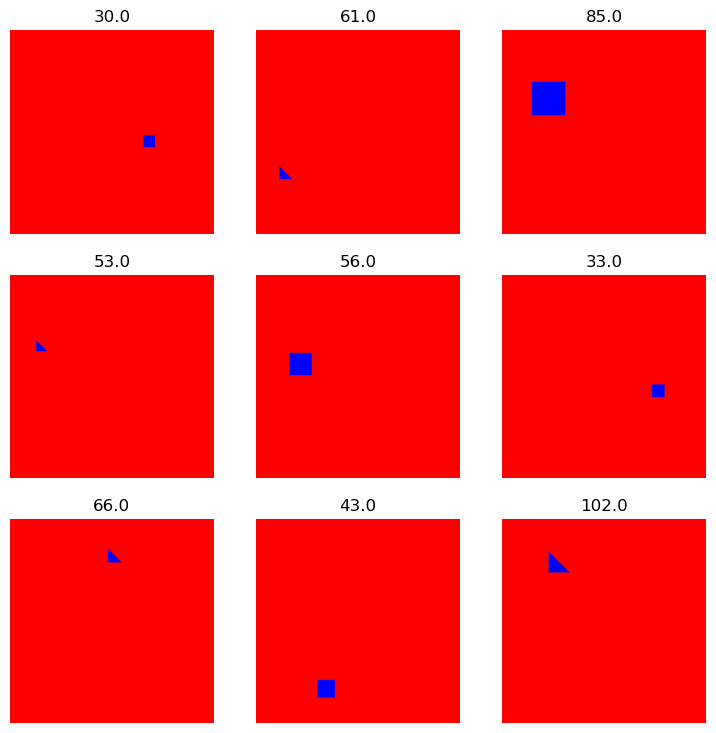

In [8]:
dls.show_batch()

The next step is to create the FastAI Learner, which combines the dataloaders, neural-network architecture, and evaluation metric used during training.

Because the model receives images as input, this tutorial uses FastAI's vision_learner.

This example uses a pretrained ResNet-34 architecture (resnet34). Smaller or larger ResNet architectures can be substituted depending on the complexity of the dataset, available computational resources, and required performance.

The evaluation metric used here is root mean square error (RMSE), which measures the typical magnitude of the difference between the predicted and target numerical values. Other evaluation approaches are discussed in the Chapter 2 appendix.


In [9]:
# Create and train the learner
learn = vision_learner(dls, resnet34, metrics=rmse)


Before training, FastAI's learning-rate finder can be used to identify a suitable learning rate.

The resulting plot shows how the training loss changes as the learning rate is increased. A useful learning rate is generally selected from the region where the loss is decreasing consistently, before the learning rate becomes large enough to destabilise training.

In this tutorial, FastAI returns both minimum-loss and steepest-slope suggestions, and the steepest-slope value is subsequently used for training. The plot can also be inspected manually if the automatic suggestion is unsuitable.

Further discussion of learning-rate selection is provided in the Chapter 2 appendix.


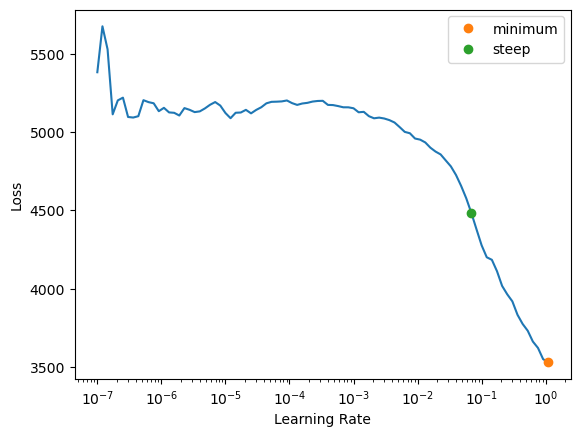

In [10]:
lr_min,lr_steep = learn.lr_find(suggest_funcs=(minimum, steep))

The model can now be trained.

Because resnet34 is loaded with pretrained weights, this tutorial uses FastAI's fine_tune method rather than training the network from randomly initialised weights. Fine-tuning allows the pretrained model to adapt its existing image features to the new regression task.

The first argument specifies the number of training epochs, while base_lr specifies the learning rate identified in the previous step. More detailed discussion of training methods, epochs, and training outputs is provided in the Chapter 2 appendix.


In [11]:
learn.fine_tune(25, base_lr=lr_steep)

epoch,train_loss,valid_loss,_rmse,time
0,4004.689453,818.431152,28.608236,00:07


epoch,train_loss,valid_loss,_rmse,time
0,1000.840820,55999.250000,236.641617,00:08
1,562.231812,1639.758911,40.493935,00:08
2,421.659760,3182.397705,56.412746,00:07
3,335.080414,1113.247803,33.365368,00:07
4,267.994415,1182.448120,34.386742,00:07
5,216.508362,235.860153,15.357739,00:07
6,189.331451,117.872696,10.856919,00:07
7,159.939468,59.808331,7.733584,00:07
8,138.833694,34.967014,5.913291,00:07
9,124.628731,32.745426,5.722363,00:07


After training, the model should be evaluated to determine whether training behaved appropriately and whether its predictions are sufficiently accurate for the intended application.

There are many approaches to regression-model evaluation. This tutorial demonstrates two useful introductory methods: examining the training and validation losses and comparing predicted values with their corresponding target values.


The first evaluation step is to plot the training and validation loss values across the training epochs.

These curves provide information about how the model learned during training and can help identify problems such as overfitting, underfitting, or training that stopped before convergence. Loss curves do not directly establish whether the model is sufficiently accurate for its intended use, but they are useful for diagnosing the training process. Further discussion is provided in the Chapter 2 appendix.


<bound method Recorder.plot_loss of Recorder>


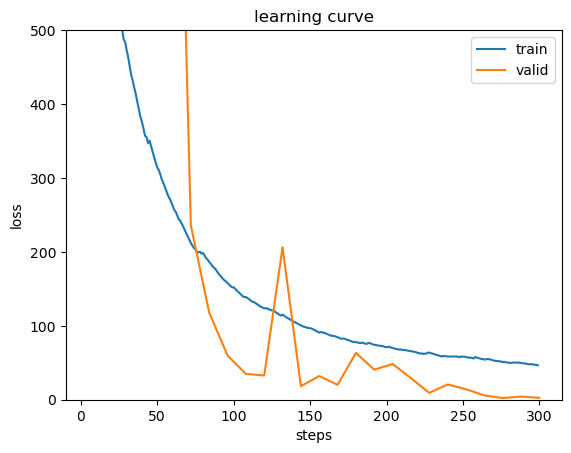

In [12]:
# Plot the losses
learn.recorder.plot_loss()
print(learn.recorder.plot_loss)
# Set the y-axis limits (replace with your desired limits)
plt.ylim(0, 500)  # sets y-axis limits 
# Show the plot with updated y-limits
plt.show()

In a successful training run, the training and validation losses should generally decrease and then stabilise. A sustained increase in validation loss while training loss continues to decrease can indicate overfitting, while both losses continuing to decrease at the end of training can indicate that additional training may still improve the model. These patterns should be interpreted alongside task-specific performance metrics rather than using a fixed numerical difference between the two losses.


Regression performance can also be evaluated by directly comparing the model predictions with the corresponding ground-truth target values.

A simple way to visualise this relationship is to plot the predicted value against the target value for every sample in the validation dataset. The following code extracts the validation predictions and targets and generates this comparison.


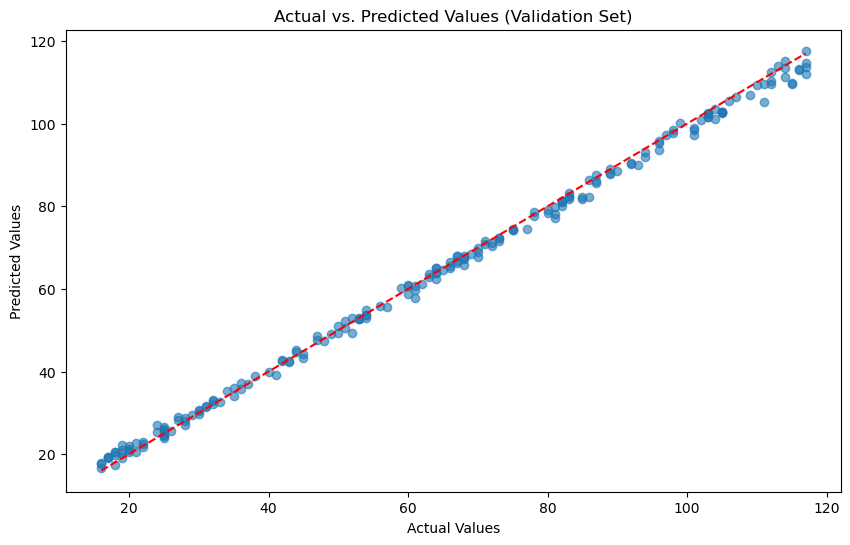

In [13]:

# extract predictions vs target value for the validatin dataset
preds, targets = learn.get_preds(ds_idx=1)  # ds_idx=1 for the validation set


import matplotlib.pyplot as plt

# Convert tensors to numpy arrays if necessary
actual_values = targets.numpy()
predicted_values = preds.numpy()

# Plotting
plt.figure(figsize=(10, 6))
plt.scatter(actual_values, predicted_values, alpha=0.6)
plt.plot([actual_values.min(), actual_values.max()], [actual_values.min(), actual_values.max()], color='red', linestyle='--')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs. Predicted Values (Validation Set)')
plt.show()

For an accurate regression model, the predicted values should cluster around the line representing agreement between prediction and target.

The distribution of points around this line can also help identify ranges of the target variable where the model performs less reliably or shows systematic bias.


Exporting and using the trained model


Saving the file into a pkl file 

In [15]:
learn.export('exported_Regression_model.pkl')

Loading an exported model

An exported FastAI learner can be loaded using load_learner() by providing the path to the exported .pkl file.

For simple image inputs, an image or image path can then be supplied directly to the loaded learner. More complex models may also require any custom functions or classes used when the learner was originally created to be available when the model is loaded.

The loaded object provides the same FastAI Learner interface used during training and can therefore be used directly for inference.


In [16]:

def get_inputs(row):
    # Convert image path to PILImage
    image_data = PILImage.create(row['im cage_path'])
    return image_data 

Imported_model = load_learner('exported_Regression_model.pkl')   # using learner2 to show its loading

C:\Users\bowan\anaconda3\Lib\site-packages\fastai\learner.py:455: UserWarning: load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.
If you only need to load model weights and optimizer state, use the safe `Learner.load` instead.
  warn("load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.\nIf you only need to load model weights and optimizer state, use the safe `Learner.load` instead.")


The following example selects an image from the dataframe and passes it to the exported model for inference.

FastAI's predict method returns the regression prediction in several related forms that can be inspected or converted as required by the downstream analysis.


In [17]:
paths = df['image_path'] # I'm cheating as I reusing the dataframe setup earlier you load in a testing dataframe.
i = 1 # row/sample number from the dataframe
image_data = PILImage.create(paths[i]) # just gets a generic image
Prediction_list, Prediction_tensor1 , Prediction_tensor2 = Imported_model.predict(image_data)



In [18]:
print(Prediction_list)
print(Prediction_tensor1)
print(Prediction_tensor2)

(94.6441421508789,)
tensor([94.6441])
tensor([94.6441])


For this regression model, predict returns three related outputs:

Prediction_list: the predicted numerical value in the decoded prediction format.

Prediction_tensor1: the predicted numerical value as a tensor.

Prediction_tensor2: the corresponding raw model output returned by FastAI.

For a simple single-output regression model, these values represent the same underlying prediction in different forms.


Displaying the input image

The following code displays the image used for inference so that the input can be inspected alongside the numerical prediction.


<Axes: >

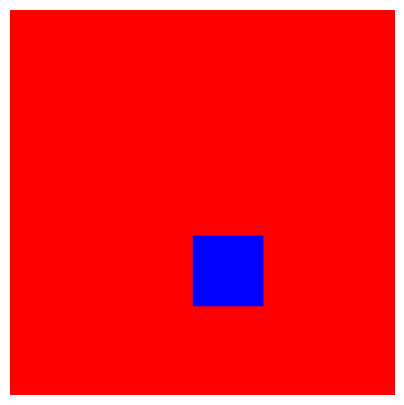

In [19]:
image_data.show()

This completes the basic image-regression workflow. The tutorial has demonstrated how to organise image and numerical target data, construct a FastAI DataBlock, create and train a pretrained image-regression model, evaluate its performance, export the trained model, and use it to generate predictions for new images. The same workflow can be adapted to other image-regression problems by replacing the example dataset and adjusting the target variable, model, and training settings as required.
